In [8]:
import numpy as np

import solarpy as sp
from solarpy import irradiance_on_plane

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from datetime import datetime, timedelta, time

In [5]:
vnorm = np.array([0, 0, -1])
height = 0
date = datetime(2020,11,19,13,1)
latitude = 23.5

irradiance_on_plane(vnorm,height, date,latitude)

753.8383601492405

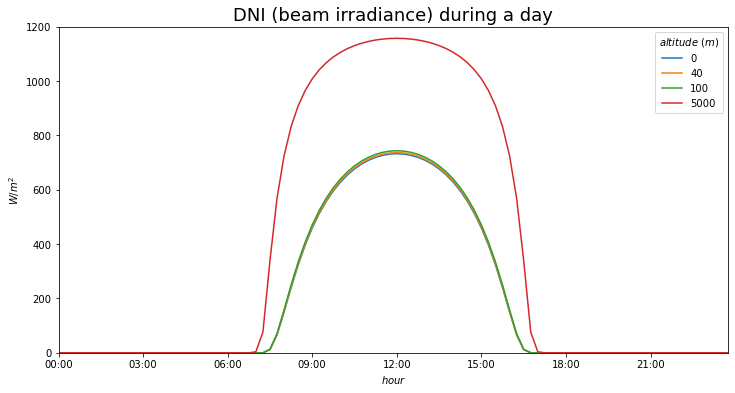

In [57]:
# Beam irradiance on a normal plane: Irradiance during the day on a plane always perpendicular to the solar beam

date = datetime(2020,11,19)
lat = 41

fig, ax = plt.subplots(figsize=(12,6))

for h in (0,40,100,5000):
    t = [date + timedelta(minutes=i) for i in range(0, 4*15 * 24, 15)]
    G = [sp.beam_irradiance(h,i,lat) for i in t]
    
    ax.plot(t, G, label=h)
    myFmt = mdates.DateFormatter('%H:%M')
    ax.xaxis.set_major_formatter(myFmt)
    
plt.autoscale(enable=True, axis='x', tight=True)
plt.ylim(0, 1200)
plt.xlabel('$hour$')
plt.ylabel('$W/m^2$')
plt.title('DNI (beam irradiance) during a day', fontsize=18)
ax.legend(title="$altitude$ $(m)$")
#plt.grid()

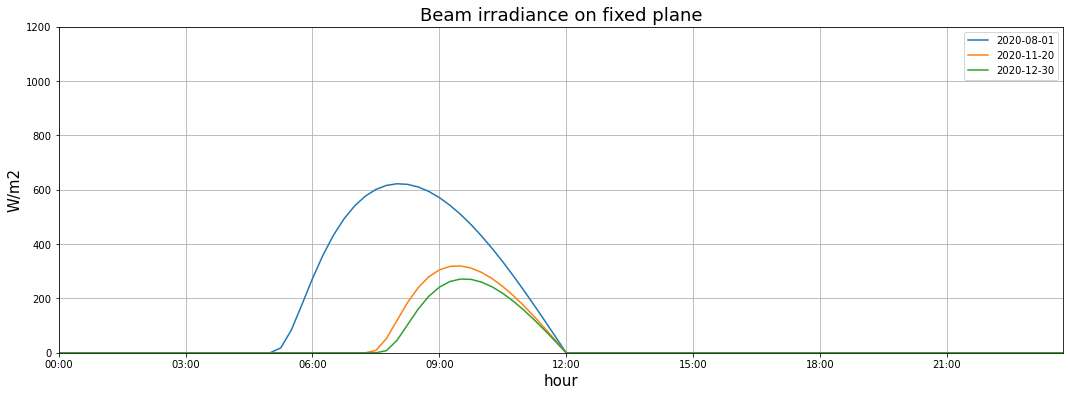

In [58]:
# irradiance on a fixed plane: irradiance during different days on a fixed plane defined by its normal vector

vnorm = np.array([0, 1, 0])  # plane pointing eastwards

date1 = datetime(2020,8,1)
date2 = datetime(2020,11,20)
date3 = datetime(2020,12,30)

lat = 41
h = 40

fig, ax = plt.subplots(figsize=(18, 6))

for dt in (date1, date2, date3):
    t = [dt + timedelta(minutes=i) for i in range(0, 4*15 * 24, 15)]
    G = [sp.irradiance_on_plane(vnorm, h, i, lat) for i in t]

    # necessary as matplotlib expects a datetime.datetime, not a datetime.time
    t_ = [datetime.combine(datetime(2019, 1, 1), i) for i in [i.time() for i in t]]    
    plt.plot(t_, G, label=str(dt.date()))
    
myFmt = mdates.DateFormatter('%H:%M')
ax.xaxis.set_major_formatter(myFmt)

plt.autoscale(enable=True, axis='x', tight=True)
plt.ylim(0, 1200)
plt.xlabel('hour', fontsize=15)
plt.ylabel('W/m2', fontsize=15)
plt.title('Beam irradiance on fixed plane', fontsize=18)
plt.legend()
plt.grid(True)
plt.show()
